# Лабораторная работа № 4. Байесовская сеть

**Цель:** представить зависимости между случайными величинами с помощью байесовской сети, самостоятельно задать DAG, оценить его параметры и выполнить вероятностный вывод при наличии evidence.

В работе используется открытый набор **Breast Cancer Wisconsin (Diagnostic)** из репозитория UCI, доступный через `scikit-learn`. Источник: [описание в scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html), [карточка UCI](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic).

> Ноутбук не использует `pgmpy`: оценка таблиц условных вероятностей и точный вывод реализованы ниже явно. Это делает все допущения модели видимыми.

## 1. Данные и смысл переменных

Один объект — результат цифрового анализа изображения тонкоигольной аспирационной биопсии образования молочной железы. Целевая переменная `Diagnosis` показывает, является образование доброкачественным (`benign`) или злокачественным (`malignant`). Исходный датасет содержит 569 объектов и 30 вещественных признаков клеточных ядер.

Чтобы сеть была читаемой, выберем пять средних (`mean`) характеристик:

| Переменная сети | Исходный признак | Смысл |
|---|---|---|
| `Radius` | `mean radius` | среднее расстояние от центра ядра до границы |
| `Texture` | `mean texture` | вариативность оттенков серого |
| `Smoothness` | `mean smoothness` | локальная вариация длины радиуса |
| `Compactness` | `mean compactness` | мера $perimeter^2/area - 1$ |
| `Concavity` | `mean concavity` | выраженность вогнутых участков контура |
| `Diagnosis` | `target` | диагноз |

Ожидаем, что размер (`Radius`) и гладкость (`Smoothness`) связаны с компактностью формы, компактность — с вогнутостью, а размер, вогнутость и текстура несут информацию о диагнозе. Это содержательные предположения о геометрии измерений и диагностическом прогнозе, а не вывод только из корреляций.

In [1]:
import itertools
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import FancyArrowPatch
from sklearn.datasets import load_breast_cancer

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
plt.style.use("seaborn-v0_8-whitegrid")

raw = load_breast_cancer(as_frame=True)
source = raw.frame.copy()
source["Diagnosis"] = source["target"].map({0: "malignant", 1: "benign"})

selected = {
    "mean radius": "Radius",
    "mean texture": "Texture",
    "mean smoothness": "Smoothness",
    "mean compactness": "Compactness",
    "mean concavity": "Concavity",
}

print(f"Размер исходных данных: {source.shape[0]} строк, {len(raw.feature_names)} признаков")
display(source[list(selected) + ["Diagnosis"]].head())

Размер исходных данных: 569 строк, 30 признаков


,mean radius,mean texture,mean smoothness,mean compactness,mean concavity,Diagnosis
0,17.99,10.38,0.1184,0.2776,0.3001,malignant
1,20.57,17.77,0.0847,0.0786,0.0869,malignant
2,19.69,21.25,0.1096,0.1599,0.1974,malignant
3,11.42,20.38,0.1425,0.2839,0.2414,malignant
4,20.29,14.34,0.1003,0.1328,0.1980,malignant


## 2. Исследование и подготовка

Байесовская сеть ниже дискретна. Каждый вещественный признак разобьём по эмпирическим тертилям на состояния `low`, `medium`, `high`. Квантильная дискретизация выбрана потому, что:

1. универсальные медицинские пороги для этих измерений в датасете не заданы;
2. приблизительно равные группы уменьшают число редких конфигураций родителей;
3. три состояния сохраняют порядок и дают более содержательную картину, чем бинаризация.

Границы вычисляются по всей выборке, поэтому это описательная модель данного набора, а не честная оценка качества классификации на новых объектах.

In [2]:
continuous = source[list(selected)].rename(columns=selected)

quality = pd.DataFrame({
    "dtype": continuous.dtypes.astype(str),
    "missing": continuous.isna().sum(),
    "unique": continuous.nunique(),
    "min": continuous.min(),
    "median": continuous.median(),
    "max": continuous.max(),
})
display(quality)
print("Распределение диагнозов:")
display(source["Diagnosis"].value_counts().to_frame("count").assign(
    share=lambda x: x["count"] / x["count"].sum()
))

,dtype,missing,unique,min,median,max
Radius,float64,0,456,6.9810,13.3700,28.1100
Texture,float64,0,479,9.7100,18.8400,39.2800
Smoothness,float64,0,474,0.0526,0.0959,0.1634
Compactness,float64,0,537,0.0194,0.0926,0.3454
Concavity,float64,0,537,0.0000,0.0615,0.4268


Распределение диагнозов:


,count,share
Diagnosis,,
benign,357,0.6274
malignant,212,0.3726


In [3]:
labels = ["low", "medium", "high"]
data = pd.DataFrame(index=source.index)
cut_points = {}

for column in continuous:
    data[column], bins = pd.qcut(
        continuous[column], q=3, labels=labels, retbins=True, duplicates="drop"
    )
    data[column] = data[column].astype(str)
    cut_points[column] = bins

data["Diagnosis"] = source["Diagnosis"]

print("Границы интервалов (округлены):")
display(pd.DataFrame(cut_points, index=["min", "q33", "q67", "max"]).T.round(4))
print("Число объектов в каждом состоянии:")
display(pd.DataFrame({c: data[c].value_counts() for c in continuous}).fillna(0).astype(int))
print("Пропуски после преобразования:", int(data.isna().sum().sum()))

Границы интервалов (округлены):


,min,q33,q67,max
Radius,6.9810,12.2500,14.7733,28.1100
Texture,9.7100,17.1933,20.7400,39.2800
Smoothness,0.0526,0.0893,0.1017,0.1634
Compactness,0.0194,0.0736,0.1156,0.3454
Concavity,0.0000,0.0380,0.1026,0.4268


Число объектов в каждом состоянии:


,Radius,Texture,Smoothness,Compactness,Concavity
high,190,189,190,190,190
low,191,190,190,190,190
medium,188,190,189,189,189


Пропуски после преобразования: 0


После дискретизации в каждом состоянии непрерывного признака около 190 наблюдений. Это не гарантирует заполненность всех совместных комбинаций, поэтому при оценке CPT применим сглаживание Лапласа ($\alpha=1$): оно не позволит вероятности стать строго нулевой из-за отсутствия конкретной комбинации в ограниченной выборке.

## 3. Вопросы к модели

До построения сети сформулируем вопросы:

1. Насколько знание о большом радиусе меняет вероятность злокачественного диагноза: $P(M)$ против $P(M\mid Radius=high)$?
2. Какова вероятность злокачественного диагноза при одновременно высокой вогнутости и высокой текстуре?
3. Как высокая компактность меняет распределение вогнутости и добавляет ли что-либо знание о высокой гладкости?
4. Как последовательно добавляемые признаки меняют распределение `Diagnosis`?

## 4. Структура сети

Зададим DAG:

- `Radius → Compactness`: размер входит в геометрический контекст показателя компактности;
- `Smoothness → Compactness`: локальные изменения радиуса связаны с регулярностью/компактностью границы;
- `Compactness → Concavity`: менее компактная, нерегулярная форма обычно допускает более выраженные вогнутые участки;
- `Radius → Diagnosis`, `Concavity → Diagnosis`, `Texture → Diagnosis`: эти измерения используются как диагностические признаки.

Направления к `Diagnosis` имеют **предсказательный**, а не доказанный причинный смысл. Мы выбираем их так, чтобы вычислять распределение диагноза по измерениям. Граф ацикличен.

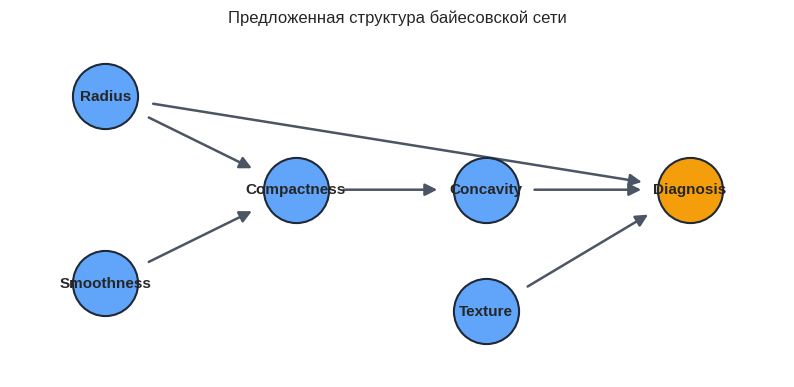

In [4]:
nodes = ["Radius", "Texture", "Smoothness", "Compactness", "Concavity", "Diagnosis"]
parents = {
    "Radius": [],
    "Texture": [],
    "Smoothness": [],
    "Compactness": ["Radius", "Smoothness"],
    "Concavity": ["Compactness"],
    "Diagnosis": ["Radius", "Texture", "Concavity"],
}
edges = [(p, node) for node, ps in parents.items() for p in ps]

positions = {
    "Radius": (0.0, 1.0),
    "Smoothness": (0.0, -1.0),
    "Compactness": (1.4, 0.0),
    "Concavity": (2.8, 0.0),
    "Texture": (2.8, -1.3),
    "Diagnosis": (4.3, 0.0),
}

fig, ax = plt.subplots(figsize=(10, 4.5))
for start, end in edges:
    arrow = FancyArrowPatch(
        positions[start], positions[end], arrowstyle="-|>", mutation_scale=18,
        linewidth=1.8, color="#4b5563", shrinkA=35, shrinkB=35,
        connectionstyle="arc3,rad=0.0"
    )
    ax.add_patch(arrow)
for node, (x, y) in positions.items():
    color = "#f59e0b" if node == "Diagnosis" else "#60a5fa"
    ax.scatter(x, y, s=2200, c=color, edgecolors="#1f2937", linewidths=1.5, zorder=3)
    ax.text(x, y, node, ha="center", va="center", fontsize=11, fontweight="bold", zorder=4)
ax.set_xlim(-0.7, 5.0)
ax.set_ylim(-2.0, 1.7)
ax.axis("off")
ax.set_title("Предложенная структура байесовской сети")
plt.show()

## 5. Оценка таблиц условных вероятностей

Для каждого узла оценивается $P(X\mid Parents(X))$. При $\alpha=1$:

$$P(X=x\mid pa)=\frac{N(x,pa)+\alpha}{N(pa)+\alpha K},$$

где $K$ — число состояний $X$. Точный вывод выполняется полным перебором всех 486 совместных состояний; для выбранной небольшой сети это прозрачно и быстро.

In [5]:
state_names = {c: labels for c in continuous.columns}
state_names["Diagnosis"] = ["benign", "malignant"]


def fit_bn(frame, graph_parents, alpha=1.0):
    # Оценка дискретных CPT с симметричным сглаживанием Дирихле.
    cpts = {}
    for node, ps in graph_parents.items():
        table = {}
        parent_configs = itertools.product(*(state_names[p] for p in ps)) if ps else [()]
        for config in parent_configs:
            mask = np.ones(len(frame), dtype=bool)
            for parent, value in zip(ps, config):
                mask &= frame[parent].to_numpy() == value
            counts = frame.loc[mask, node].value_counts().reindex(state_names[node], fill_value=0)
            probs = (counts.to_numpy(dtype=float) + alpha) / (counts.sum() + alpha * len(counts))
            table[tuple(config)] = dict(zip(state_names[node], probs))
        cpts[node] = table
    return cpts


def joint_probability(assignment, graph_parents, cpts):
    probability = 1.0
    for node, ps in graph_parents.items():
        config = tuple(assignment[p] for p in ps)
        probability *= cpts[node][config][assignment[node]]
    return probability


def query(variable, evidence, graph_parents, cpts):
    # Точное P(variable | evidence) суммированием полной совместной таблицы.
    unknown = [n for n in graph_parents if n not in evidence]
    totals = {state: 0.0 for state in state_names[variable]}
    normalizer = 0.0
    for values in itertools.product(*(state_names[n] for n in unknown)):
        assignment = dict(evidence)
        assignment.update(dict(zip(unknown, values)))
        p = joint_probability(assignment, graph_parents, cpts)
        totals[assignment[variable]] += p
        normalizer += p
    return pd.Series({state: value / normalizer for state, value in totals.items()}, name="probability")


def cpt_frame(node, graph_parents, cpts):
    ps = graph_parents[node]
    rows = []
    for config, probabilities in cpts[node].items():
        row = dict(zip(ps, config))
        row.update({f"P({state})": p for state, p in probabilities.items()})
        rows.append(row)
    return pd.DataFrame(rows)


cpts = fit_bn(data, parents, alpha=1.0)
print("CPT: Concavity | Compactness")
display(cpt_frame("Concavity", parents, cpts).round(4))
print("CPT: Diagnosis | Radius, Texture, Concavity")
display(cpt_frame("Diagnosis", parents, cpts).round(4))

CPT: Concavity | Compactness


,Compactness,P(low),P(medium),P(high)
0,low,0.7876,0.2073,0.0052
1,medium,0.1927,0.6198,0.1875
2,high,0.0207,0.1710,0.8083


CPT: Diagnosis | Radius, Texture, Concavity


,Radius,Texture,Concavity,P(benign),P(malignant)
0,low,low,low,0.9800,0.0200
1,low,low,medium,0.9697,0.0303
2,low,low,high,0.6000,0.4000
3,low,medium,low,0.9487,0.0513
4,low,medium,medium,0.9615,0.0385
5,low,medium,high,0.6364,0.3636
6,low,high,low,0.9615,0.0385
7,low,high,medium,0.9333,0.0667
8,low,high,high,0.5000,0.5000
9,medium,low,low,0.9737,0.0263


В первой таблице можно непосредственно проверить, растёт ли вероятность высокой вогнутости вместе с компактностью. Во второй — как сочетания трёх диагностических признаков перераспределяют вероятность диагноза. Для редких сочетаний сглаживание делает оценки осторожнее; поэтому экстремальные строки не следует трактовать как точные медицинские риски.

In [6]:
# Сопоставим некоторые CPT с простыми эмпирическими частотами без сглаживания.
checks = []
for compactness in labels:
    subset = data[data["Compactness"] == compactness]
    checks.append({
        "Compactness": compactness,
        "n": len(subset),
        "empirical P(Concavity=high)": (subset["Concavity"] == "high").mean(),
        "CPT P(Concavity=high)": cpts["Concavity"][(compactness,)]["high"],
    })
display(pd.DataFrame(checks).round(4))

,Compactness,n,empirical P(Concavity=high),CPT P(Concavity=high)
0,low,190,0.0000,0.0052
1,medium,189,0.1852,0.1875
2,high,190,0.8158,0.8083


Разница между частотой и CPT мала и объясняется сглаживанием Лапласа. Если вероятность высокой вогнутости резко увеличивается от `low` к `high` компактности, это согласуется с геометрическим смыслом признаков. Однако оба показателя вычислены по одному изображению, поэтому зависимость отчасти отражает связанные определения измерений.

## 6. Вероятностные запросы

In [7]:
q1_prior = query("Diagnosis", {}, parents, cpts)
q1_radius = query("Diagnosis", {"Radius": "high"}, parents, cpts)
q2 = query("Diagnosis", {"Concavity": "high", "Texture": "high"}, parents, cpts)
q3_prior = query("Concavity", {}, parents, cpts)
q3_compact = query("Concavity", {"Compactness": "high"}, parents, cpts)
q3_both = query(
    "Concavity", {"Compactness": "high", "Smoothness": "high"}, parents, cpts
)

answers = pd.DataFrame({
    "P(Diagnosis)": q1_prior,
    "P(Diagnosis | Radius=high)": q1_radius,
    "P(Diagnosis | Concavity=high, Texture=high)": q2,
})
print("Запросы 1–2:")
display(answers.round(4))

concavity_answers = pd.DataFrame({
    "P(Concavity)": q3_prior,
    "P(Concavity | Compactness=high)": q3_compact,
    "P(Concavity | Compactness=high, Smoothness=high)": q3_both,
})
print("Запрос 3:")
display(concavity_answers.round(4))

Запросы 1–2:


,P(Diagnosis),P(Diagnosis | Radius=high),"P(Diagnosis | Concavity=high, Texture=high)"
benign,0.6304,0.2702,0.1573
malignant,0.3696,0.7298,0.8427


Запрос 3:


,P(Concavity),P(Concavity | Compactness=high),"P(Concavity | Compactness=high, Smoothness=high)"
low,0.3329,0.0207,0.0207
medium,0.3417,0.1710,0.1710
high,0.3255,0.8083,0.8083


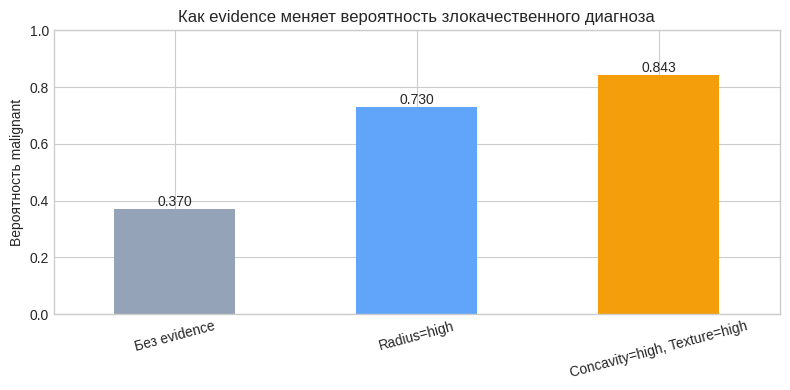

Высокий Radius меняет P(malignant) с 0.370 до 0.730; сочетание высоких Concavity и Texture — до 0.843.
Высокая Compactness меняет P(Concavity=high) с 0.325 до 0.808. При уже известной Compactness дополнительная Smoothness почти не влияет напрямую: в графе Concavity условно независима от Smoothness при заданной Compactness.


In [8]:
malignant_results = pd.Series({
    "Без evidence": q1_prior["malignant"],
    "Radius=high": q1_radius["malignant"],
    "Concavity=high, Texture=high": q2["malignant"],
})

ax = malignant_results.plot(kind="bar", color=["#94a3b8", "#60a5fa", "#f59e0b"], figsize=(8, 4))
ax.set_ylabel("Вероятность malignant")
ax.set_ylim(0, 1)
ax.set_title("Как evidence меняет вероятность злокачественного диагноза")
ax.tick_params(axis="x", rotation=15)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f")
plt.tight_layout()
plt.show()

print(
    f"Высокий Radius меняет P(malignant) с {q1_prior['malignant']:.3f} "
    f"до {q1_radius['malignant']:.3f}; сочетание высоких Concavity и Texture — "
    f"до {q2['malignant']:.3f}."
)
print(
    f"Высокая Compactness меняет P(Concavity=high) с {q3_prior['high']:.3f} "
    f"до {q3_compact['high']:.3f}. При уже известной Compactness дополнительная "
    f"Smoothness почти не влияет напрямую: в графе Concavity условно независима от "
    f"Smoothness при заданной Compactness."
)

Интерпретация относится к распределению в данной выборке и к принятой структуре. Это не индивидуальная медицинская оценка. В частности, сеть не учитывает возраст, процедуру отбора пациентов и неопределённость дискретизации.

## 7. Последовательный эксперимент с evidence

Целевая переменная — `Diagnosis`. Последовательно добавим `Radius=high`, затем `Concavity=high`, затем `Texture=high`. В графе все три узла являются непосредственными родителями диагноза, поэтому каждый новый факт потенциально меняет его распределение.

,benign,malignant
Ничего не известно,0.6304,0.3696
Radius=high,0.2702,0.7298
+ Concavity=high,0.0701,0.9299
+ Texture=high,0.0123,0.9877


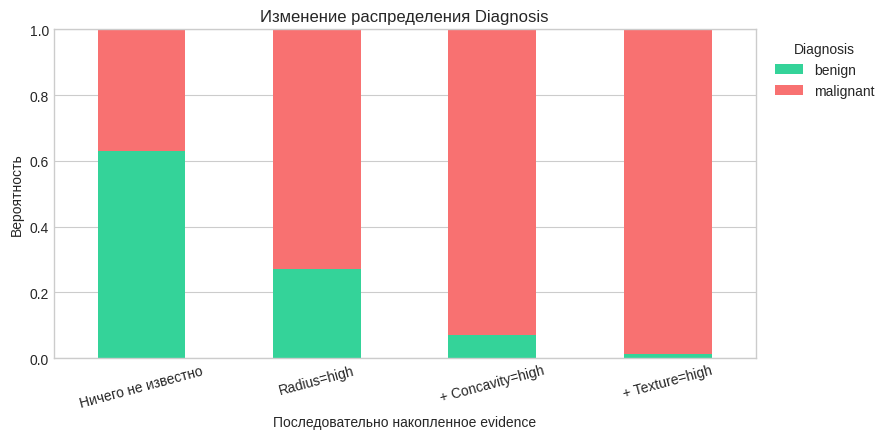

In [9]:
evidence_steps = [
    ("Ничего не известно", {}),
    ("Radius=high", {"Radius": "high"}),
    ("+ Concavity=high", {"Radius": "high", "Concavity": "high"}),
    ("+ Texture=high", {"Radius": "high", "Concavity": "high", "Texture": "high"}),
]

experiment = pd.DataFrame({
    name: query("Diagnosis", evidence, parents, cpts)
    for name, evidence in evidence_steps
}).T
display(experiment.round(4))

ax = experiment[["benign", "malignant"]].plot(
    kind="bar", stacked=True, color=["#34d399", "#f87171"], figsize=(9, 4.5)
)
ax.set_ylabel("Вероятность")
ax.set_xlabel("Последовательно накопленное evidence")
ax.set_ylim(0, 1)
ax.legend(title="Diagnosis", loc="upper left", bbox_to_anchor=(1.01, 1))
ax.tick_params(axis="x", rotation=15)
ax.set_title("Изменение распределения Diagnosis")
plt.tight_layout()
plt.show()

Столбцы показывают не «вклад» признака сам по себе, а пересчёт условного распределения при накопленном evidence. Изменение может быть немонотонным: конкретная CPT кодирует взаимодействие сочетаний состояний, а не обязательное одинаковое действие признака во всех контекстах.

## 8. Анализ чувствительности к структуре

Удалим ребро `Compactness → Concavity`, заново оценим CPT и сравним запрос

$$P(Diagnosis\mid Compactness=high, Radius=medium).$$

В исходной сети `Compactness` передаёт информацию диагнозу по пути `Compactness → Concavity → Diagnosis`. После удаления ребра этот путь исчезает, и при фиксированном `Radius` evidence о компактности не должно менять диагноз.

In [10]:
parents_reduced = {node: list(ps) for node, ps in parents.items()}
parents_reduced["Concavity"] = []
cpts_reduced = fit_bn(data, parents_reduced, alpha=1.0)

structure_comparison = pd.DataFrame({
    "Исходная сеть": query(
        "Diagnosis", {"Compactness": "high", "Radius": "medium"}, parents, cpts
    ),
    "Без Compactness→Concavity": query(
        "Diagnosis", {"Compactness": "high", "Radius": "medium"},
        parents_reduced, cpts_reduced
    ),
    "Только Radius=medium (исходная)": query(
        "Diagnosis", {"Radius": "medium"}, parents, cpts
    ),
}).T
display(structure_comparison.round(4))

delta = (
    structure_comparison.loc["Без Compactness→Concavity", "malignant"]
    - structure_comparison.loc["Исходная сеть", "malignant"]
)
print(f"Изменение P(malignant) после удаления ребра: {delta:+.4f}")

,benign,malignant
Исходная сеть,0.5138,0.4862
Без Compactness→Concavity,0.7239,0.2761
Только Radius=medium (исходная),0.7345,0.2655


Изменение P(malignant) после удаления ребра: -0.2101


Результат меняется, потому что DAG задаёт факторизацию совместного распределения и набор условных независимостей. В сокращённой модели `Compactness` и `Concavity` независимы, а значит evidence о компактности перестаёт доходить до диагноза через вогнутость. Значение сокращённой модели близко к запросу только при `Radius=medium`; небольшая разница остаётся из-за повторной оценки CPT и сглаживания Лапласа в изменённой факторизации.

Направление ребра трудно уверенно выбрать только по наблюдаемым данным: разные DAG могут описывать один и тот же набор условных независимостей (марковская эквивалентность). Для причинной ориентации нужны предметные знания, временной порядок, интервенции или дополнительные допущения.

## 9. Можно ли считать сеть причинной?

**Нет, построенная сеть не является доказанной причинной моделью.** Стрелки выбраны на основании смысла признаков и удобной предсказательной факторизации наблюдаемого распределения. Изображение и диагноз наблюдаются совместно; мы не проводили интервенций и не контролировали все возможные смешивающие факторы.

Некоторые геометрические связи (`Smoothness → Compactness → Concavity`) правдоподобны как отношения между характеристиками формы, но даже здесь направление частично обусловлено тем, как признаки математически определены. Стрелки к `Diagnosis` особенно важно понимать как предсказательные: изменение измеренного радиуса само по себе не является медицинской интервенцией, которая обязательно изменит истинное заболевание.

## 10. Итог

- Компактная дискретная сеть позволила получить согласованное совместное распределение шести переменных и отвечать на условные вероятностные вопросы.
- Наиболее заметную информацию о диагнозе дают сочетания состояний радиуса, вогнутости и текстуры; компактность информативна косвенно через вогнутость.
- Evidence пересчитывает всё распределение целевой переменной; последовательное добавление фактов может существенно сдвигать вероятность `malignant`.
- Удаление одного ребра разрывает путь передачи информации и меняет результат запроса, поэтому вывод зависит не только от данных, но и от структуры DAG.
- Ограничения: квантильная дискретизация теряет информацию; CPT для некоторых комбинаций оцениваются по малому числу наблюдений; структура задана вручную; нет валидации прогноза, учёта смещения выборки и оснований для причинного вывода.